# MINI PROJECT: IPL DATA ANALYSIS

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab

This notebook is prepared to run directly in Google Colab. You do **not** need to manually download the large delivery CSV.

**Dataset source:** public IPL dataset repository. The repository contains match data and ball-by-ball CSV data.  
Source: https://github.com/avinashyadav16/ipl-analytics

The notebook downloads the two CSV files directly when it is run.


In [2]:
# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. LOAD THE DATA

The files are loaded directly from GitHub, so there is no need to upload the large CSV files manually.


In [3]:
# 2. LOAD DATA DIRECTLY FROM THE PUBLIC DATASET
MATCHES_URL = "https://raw.githubusercontent.com/avinashyadav16/ipl-analytics/main/matches_2008-2024.csv"
DELIVERIES_URL = "https://raw.githubusercontent.com/avinashyadav16/ipl-analytics/main/deliveries_2008-2024.csv"

matches = pd.read_csv(MATCHES_URL)
deliveries = pd.read_csv(DELIVERIES_URL)

print("Matches shape:", matches.shape)
print("Deliveries shape:", deliveries.shape)


Matches shape: (1095, 20)
Deliveries shape: (260920, 17)


In [4]:
# FIRST LOOK
print("MATCHES")
display(matches.head())

print("\nDELIVERIES")
display(deliveries.head())


MATCHES


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2008,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2008,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2008,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2008,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2008,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan



DELIVERIES


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NA,NA,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NA,NA,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN


In [5]:
# COLUMNS AND DATA TYPES
print("Match columns:")
print(matches.columns.tolist())

print("\nDelivery columns:")
print(deliveries.columns.tolist())

print("\nMatch data types:")
display(matches.dtypes)

print("\nDelivery data types:")
display(deliveries.dtypes)


Match columns:
['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']

Delivery columns:
['match_id ', 'inning ', 'batting_team                ', 'bowling_team                ', 'over ', 'ball ', 'batter                  ', 'bowler                  ', 'non_striker             ', 'batsman_runs ', 'extra_runs ', 'total_runs ', 'extras_type ', 'is_wicket ', 'player_dismissed        ', 'dismissal_kind        ', 'fielder']

Match data types:


,0
id,int64
season,int64
city,object
date,object
match_type,object
player_of_match,object
venue,object
team1,object
team2,object
toss_winner,object



Delivery data types:


,0
match_id,int64
inning,int64
batting_team,object
bowling_team,object
over,int64
ball,int64
batter,object
bowler,object
non_striker,object
batsman_runs,int64


## 3. DATA CLEANING


In [6]:
# CHECK MISSING VALUES AND DUPLICATES
print("Missing values in matches:")
display(matches.isnull().sum())

print("Duplicate rows in matches:", matches.duplicated().sum())

print("\nMissing values in deliveries:")
display(deliveries.isnull().sum())

print("Duplicate rows in deliveries:", deliveries.duplicated().sum())


Missing values in matches:


,0
id,0
season,0
city,51
date,0
match_type,0
player_of_match,5
venue,0
team1,0
team2,0
toss_winner,0


Duplicate rows in matches: 0

Missing values in deliveries:


,0
match_id,0
inning,0
batting_team,0
bowling_team,0
over,0
ball,0
batter,0
bowler,0
non_striker,0
batsman_runs,0


Duplicate rows in deliveries: 0


In [7]:
# CLEAN MATCH DATA
matches = matches.copy()
deliveries = deliveries.copy()

matches["date"] = pd.to_datetime(matches["date"], errors="coerce")

# Standardize text columns
for col in ["city", "match_type", "player_of_match", "venue", "team1", "team2",
            "toss_winner", "toss_decision", "winner", "result", "method"]:
    if col in matches.columns:
        matches[col] = matches[col].astype("string").str.strip()

# Replace placeholder values with missing values
matches = matches.replace({"NA": np.nan, "N/A": np.nan, "": np.nan})

# Remove exact duplicate match rows
matches = matches.drop_duplicates()

# Numeric columns
for col in ["season", "result_margin", "target_runs", "target_overs"]:
    if col in matches.columns:
        matches[col] = pd.to_numeric(matches[col], errors="coerce")

print("Match cleaning completed.")
display(matches.head())


Match cleaning completed.


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2008,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,<NA>,Asad Rauf,RE Koertzen
1,335983,2008,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,<NA>,MR Benson,SL Shastri
2,335984,2008,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,<NA>,Aleem Dar,GA Pratapkumar
3,335985,2008,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,<NA>,SJ Davis,DJ Harper
4,335986,2008,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,<NA>,BF Bowden,K Hariharan


In [8]:
# CLEAN DELIVERY DATA
# Convert numeric columns
delivery_numeric = [
    "ID", "Innings", "Overs", "BallNumber", "BatsmanRuns",
    "ExtrasRun", "TotalRun", "IsWicketDelivery"
]

for col in delivery_numeric:
    if col in deliveries.columns:
        deliveries[col] = pd.to_numeric(deliveries[col], errors="coerce")

# Standardize player/team text
for col in ["Batter", "Bowler", "NonStriker", "ExtraType", "PlayerOut",
            "Kind", "FieldersInvolved", "BattingTeam"]:
    if col in deliveries.columns:
        deliveries[col] = deliveries[col].astype("string").str.strip()

deliveries = deliveries.drop_duplicates()

print("Delivery cleaning completed.")
display(deliveries.head())


Delivery cleaning completed.


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NA,NA,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NA,NA,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN


## 4. CREATE USEFUL DERIVED COLUMNS

The ball-by-ball file contains the batting team. The bowling team is derived from the two teams listed for each match.


In [14]:
# ADD MATCH INFORMATION TO EACH DELIVERY

# Make the ID column names the same
deliveries["ID"] = deliveries["match_id"]

# Select match information
match_columns = [
    "ID", "season", "date", "city", "venue",
    "team1", "team2", "toss_winner", "toss_decision",
    "winner", "result", "result_margin", "player_of_match"
]

available_columns = [c for c in match_columns if c in matches.columns]

match_lookup = matches[available_columns].copy()

# Merge match information with delivery data
merged = deliveries.merge(
    match_lookup,
    on="ID",
    how="left"
)

print("Merged data shape:", merged.shape)

display(merged.head())

Merged data shape: (260920, 30)


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder,ID,season,date,city,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,player_of_match
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NA,NA,NaN,335982,2008,2008-04-18,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,BB McCullum
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN,335982,2008,2008-04-18,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,BB McCullum
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NA,NA,NaN,335982,2008,2008-04-18,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,BB McCullum
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN,335982,2008,2008-04-18,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,BB McCullum
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,,0,NA,NA,NaN,335982,2008,2008-04-18,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,BB McCullum


In [13]:
# Remove extra spaces from column names

deliveries.columns = deliveries.columns.str.strip()
matches.columns = matches.columns.str.strip()

print("Delivery columns:", deliveries.columns.tolist())
print("Match columns:", matches.columns.tolist())

Delivery columns: ['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']
Match columns: ['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2', 'ID']


## 5. BASIC ANALYSIS


In [15]:
# 1. TOTAL MATCHES
total_matches = matches["id"].nunique()
print("Total matches:", total_matches)

# 2. MATCHES PER SEASON
matches_per_season = matches.groupby("season")["id"].nunique().sort_index()
display(matches_per_season)

# 3. TOTAL TEAMS
teams = pd.unique(pd.concat([matches["team1"], matches["team2"]]).dropna())
print("Total teams:", len(teams))
print(sorted(teams))


Total matches: 1095


,id
season,
2008,58
2009,57
2010,60
2011,73
2012,74
2013,76
2014,60
2015,59
2016,60


Total teams: 19
['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Delhi Daredevils', 'Gujarat Lions', 'Gujarat Titans', 'Kings XI Punjab', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Rising Pune Supergiants', 'Royal Challengers Bangalore', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


In [16]:
# 4. TEAM WINS
team_wins = matches["winner"].dropna().value_counts()
display(team_wins)

print("Highest number of wins:")
display(team_wins.head(10))

print("Lowest number of wins among teams with recorded wins:")
display(team_wins.sort_values().head(10))


,count
winner,
Mumbai Indians,144
Chennai Super Kings,138
Kolkata Knight Riders,131
Royal Challengers Bangalore,116
Rajasthan Royals,112
Sunrisers Hyderabad,88
Kings XI Punjab,88
Delhi Daredevils,67
Delhi Capitals,48


Highest number of wins:


,count
winner,
Mumbai Indians,144
Chennai Super Kings,138
Kolkata Knight Riders,131
Royal Challengers Bangalore,116
Rajasthan Royals,112
Sunrisers Hyderabad,88
Kings XI Punjab,88
Delhi Daredevils,67
Delhi Capitals,48


Lowest number of wins among teams with recorded wins:


,count
winner,
Rising Pune Supergiants,5
Kochi Tuskers Kerala,6
Royal Challengers Bengaluru,7
Rising Pune Supergiant,10
Pune Warriors,12
Gujarat Lions,13
Lucknow Super Giants,24
Punjab Kings,24
Gujarat Titans,28


In [17]:
# 5. PLAYER OF THE MATCH
player_of_match = matches["player_of_match"].dropna().value_counts()
display(player_of_match.head(10))


,count
player_of_match,
AB de Villiers,25
CH Gayle,22
RG Sharma,19
DA Warner,18
V Kohli,18
MS Dhoni,17
RA Jadeja,16
SR Watson,16
YK Pathan,16


In [18]:
# 6. VENUE ANALYSIS
venue_count = matches["venue"].value_counts()
display(venue_count.head(10))


,count
venue,
Eden Gardens,77
Wankhede Stadium,73
M Chinnaswamy Stadium,65
Feroz Shah Kotla,60
"Rajiv Gandhi International Stadium, Uppal",49
"MA Chidambaram Stadium, Chepauk",48
Sawai Mansingh Stadium,47
Dubai International Cricket Stadium,46
"Wankhede Stadium, Mumbai",45


In [19]:
# 7. TOSS DECISION
toss_decision = matches["toss_decision"].value_counts()
display(toss_decision)


,count
toss_decision,
field,704
bat,391


In [20]:
# 8. DID THE TOSS WINNER ALSO WIN THE MATCH?
toss_match = matches.dropna(subset=["toss_winner", "winner"]).copy()
toss_match["toss_winner_won_match"] = toss_match["toss_winner"] == toss_match["winner"]

toss_win_count = toss_match["toss_winner_won_match"].value_counts()
display(toss_win_count)

toss_win_percentage = toss_match["toss_winner_won_match"].mean() * 100
print(f"Toss winner also won the match: {toss_win_percentage:.2f}%")


,count
toss_winner_won_match,
True,554
False,536


Toss winner also won the match: 50.83%


In [21]:
# 9. WINNING MARGINS
print("Highest win margin by runs:")
display(matches[matches["result"].eq("runs")].nlargest(10, "result_margin")[
    ["season","team1","team2","winner","result_margin","player_of_match"]
])

print("\nHighest win margin by wickets:")
display(matches[matches["result"].eq("wickets")].nlargest(10, "result_margin")[
    ["season","team1","team2","winner","result_margin","player_of_match"]
])


Highest win margin by runs:


,season,team1,team2,winner,result_margin,player_of_match
620,2017,Delhi Daredevils,Mumbai Indians,Mumbai Indians,146.0,LMP Simmons
560,2016,Royal Challengers Bangalore,Gujarat Lions,Royal Challengers Bangalore,144.0,AB de Villiers
0,2008,Royal Challengers Bangalore,Kolkata Knight Riders,Kolkata Knight Riders,140.0,BB McCullum
496,2015,Royal Challengers Bangalore,Kings XI Punjab,Royal Challengers Bangalore,138.0,CH Gayle
352,2013,Royal Challengers Bangalore,Pune Warriors,Royal Challengers Bangalore,130.0,CH Gayle
706,2019,Sunrisers Hyderabad,Royal Challengers Bangalore,Sunrisers Hyderabad,118.0,JM Bairstow
1009,2023,Royal Challengers Bangalore,Rajasthan Royals,Royal Challengers Bangalore,112.0,WD Parnell
236,2011,Kings XI Punjab,Royal Challengers Bangalore,Kings XI Punjab,111.0,AC Gilchrist
1039,2024,Kolkata Knight Riders,Delhi Capitals,Kolkata Knight Riders,106.0,SP Narine
55,2008,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,105.0,SR Watson



Highest win margin by wickets:


,season,team1,team2,winner,result_margin,player_of_match
12,2008,Mumbai Indians,Deccan Chargers,Deccan Chargers,10.0,AC Gilchrist
60,2009,Delhi Daredevils,Kings XI Punjab,Delhi Daredevils,10.0,DL Vettori
124,2010,Royal Challengers Bangalore,Rajasthan Royals,Royal Challengers Bangalore,10.0,JH Kallis
239,2011,Mumbai Indians,Rajasthan Royals,Rajasthan Royals,10.0,SR Watson
317,2012,Rajasthan Royals,Mumbai Indians,Mumbai Indians,10.0,DR Smith
332,2013,Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,10.0,MEK Hussey
482,2015,Delhi Daredevils,Royal Challengers Bangalore,Royal Challengers Bangalore,10.0,VR Aaron
531,2016,Gujarat Lions,Sunrisers Hyderabad,Sunrisers Hyderabad,10.0,B Kumar
579,2017,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,10.0,CA Lynn
611,2017,Kings XI Punjab,Delhi Daredevils,Kings XI Punjab,10.0,Sandeep Sharma


In [23]:
# 10. TOP RUN SCORERS

top_run_scorers = (
    deliveries.groupby("batter")["batsman_runs"]
    .sum()
    .sort_values(ascending=False)
)

display(top_run_scorers.head(10))


,batsman_runs
batter,
V Kohli,8014
S Dhawan,6769
RG Sharma,6630
DA Warner,6567
SK Raina,5536
MS Dhoni,5243
AB de Villiers,5181
CH Gayle,4997
RV Uthappa,4954


In [25]:
# 11. TOP WICKET TAKERS

# Select deliveries where a wicket occurred
wicket_data = deliveries[deliveries["is_wicket"] == 1].copy()

# Exclude dismissals that are not credited to the bowler
bowling_dismissals = wicket_data[
    ~wicket_data["dismissal_kind"].isin(
        ["run out", "retired hurt", "obstructing the field"]
    )
]

# Count wickets taken by each bowler
top_wicket_takers = (
    bowling_dismissals["bowler"]
    .value_counts()
    .sort_values(ascending=False)
)

display(top_wicket_takers.head(10))

,count
bowler,
YS Chahal,213
DJ Bravo,207
PP Chawla,201
SP Narine,200
R Ashwin,198
B Kumar,195
SL Malinga,188
A Mishra,183
JJ Bumrah,182


In [27]:
# 12. SEASON-WISE RUNS

season_runs = (
    merged.groupby("season")["total_runs"]
    .sum()
    .sort_index()
)

display(season_runs)

,total_runs
season,
2008,17937
2009,16353
2010,18883
2011,21154
2012,22453
2013,22602
2014,18931
2015,18353
2016,18862


In [29]:
# 13. SEASON-WISE WICKETS

season_wickets = (
    merged[merged["is_wicket"] == 1]
    .groupby("season")["is_wicket"]
    .sum()
    .sort_index()
)

display(season_wickets)

,is_wicket
season,
2008,690
2009,698
2010,725
2011,813
2012,858
2013,912
2014,674
2015,691
2016,666


In [31]:
# 14. AVERAGE RUNS PER MATCH

average_runs_per_match = (
    merged.groupby("ID")["total_runs"]
    .sum()
    .mean()
)

print(f"Average total runs per match: {average_runs_per_match:.2f}")

Average total runs per match: 317.59


In [43]:
# 15. TEAM PERFORMANCE SUMMARY
team_performance = team_wins.rename("Wins").to_frame()
team_matches = pd.concat([
    matches[["team1"]].rename(columns={"team1":"team"}),
    matches[["team2"]].rename(columns={"team2":"team"})
])["team"].value_counts().rename("Matches")

team_performance = team_matches.to_frame().join(team_performance, how="left").fillna(0)
team_performance["Win_Percentage"] = (
    team_performance["Wins"] / team_performance["Matches"] * 100
)
team_performance = team_performance.sort_values("Wins", ascending=False)

display(team_performance)


,Matches,Wins,Win_Percentage
team,,,
Mumbai Indians,261,144,55.172414
Chennai Super Kings,238,138,57.983193
Kolkata Knight Riders,251,131,52.191235
Royal Challengers Bangalore,240,116,48.333333
Rajasthan Royals,221,112,50.678733
Kings XI Punjab,190,88,46.315789
Sunrisers Hyderabad,182,88,48.351648
Delhi Daredevils,161,67,41.614907
Delhi Capitals,91,48,52.747253


## 6. REQUIRED VISUALIZATIONS


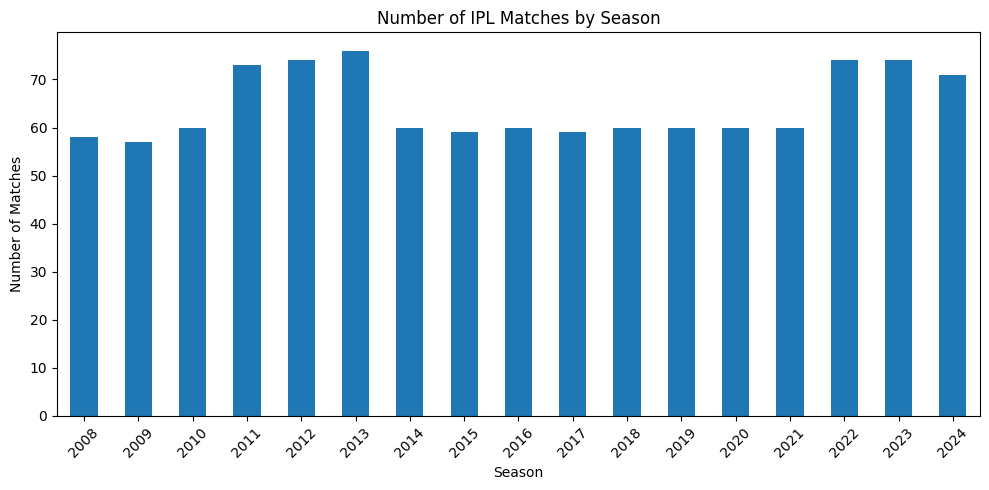

In [44]:
# 1. MATCHES BY SEASON
plt.figure(figsize=(10,5))
matches_per_season.plot(kind="bar")
plt.title("Number of IPL Matches by Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


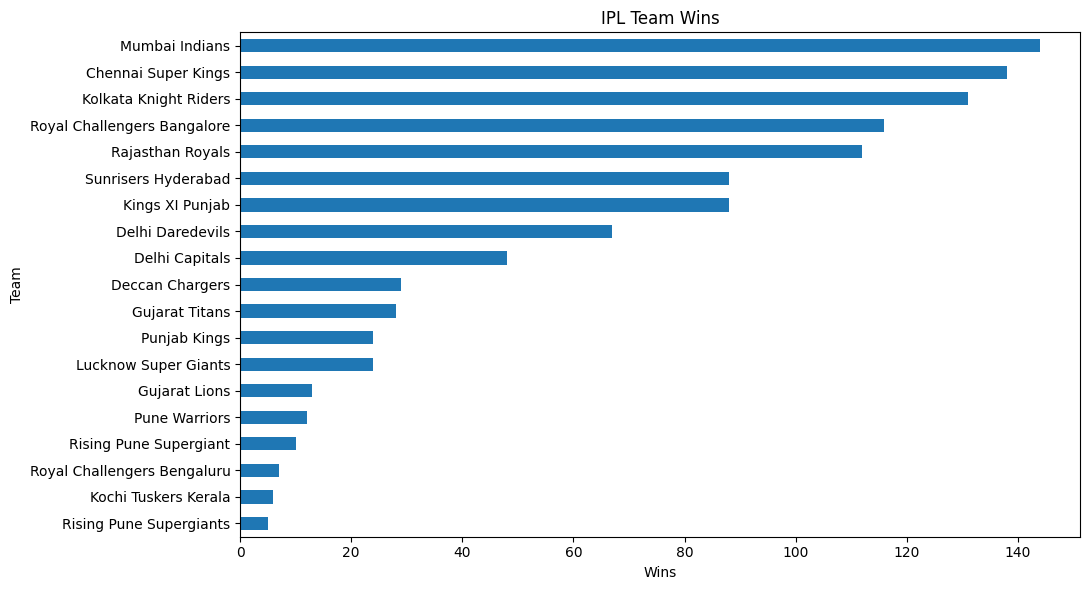

In [45]:
# 2. TEAM WINS
plt.figure(figsize=(11,6))
team_wins.sort_values().plot(kind="barh")
plt.title("IPL Team Wins")
plt.xlabel("Wins")
plt.ylabel("Team")
plt.tight_layout()
plt.show()


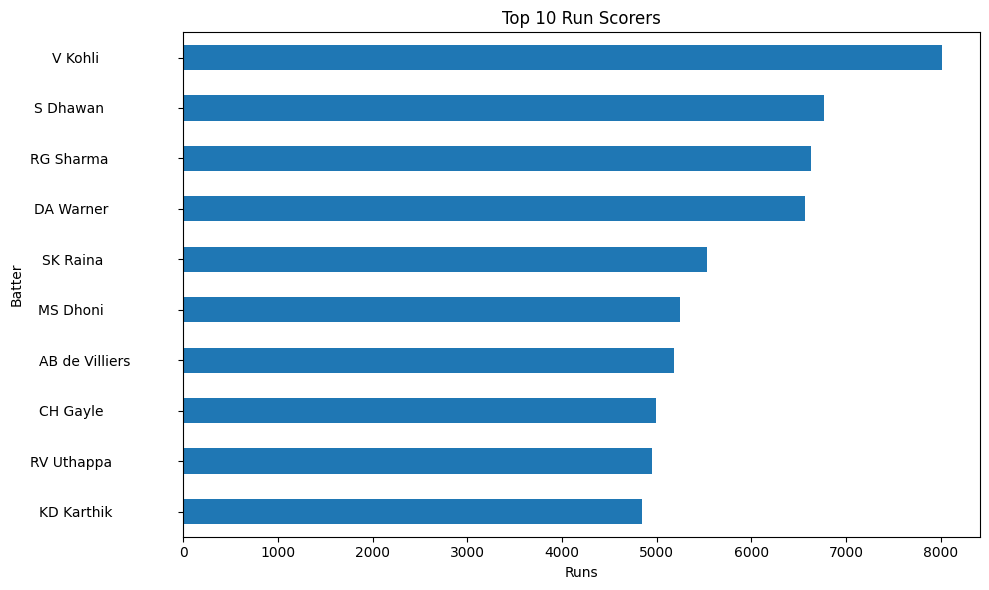

In [46]:
# 3. TOP 10 RUN SCORERS
plt.figure(figsize=(10,6))
top_run_scorers.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Run Scorers")
plt.xlabel("Runs")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()


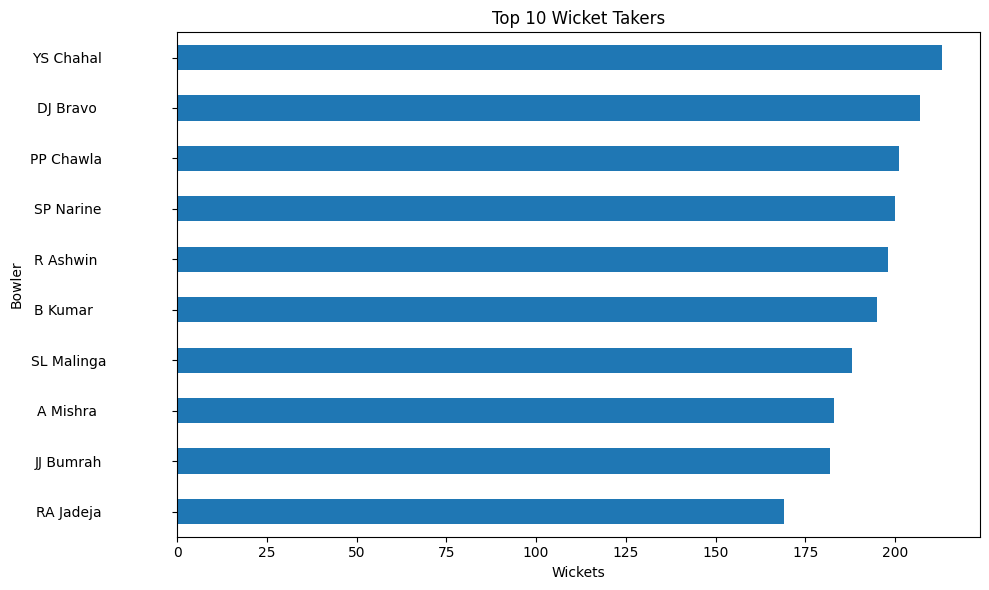

In [47]:
# 4. TOP 10 WICKET TAKERS
plt.figure(figsize=(10,6))
top_wicket_takers.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Wicket Takers")
plt.xlabel("Wickets")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()


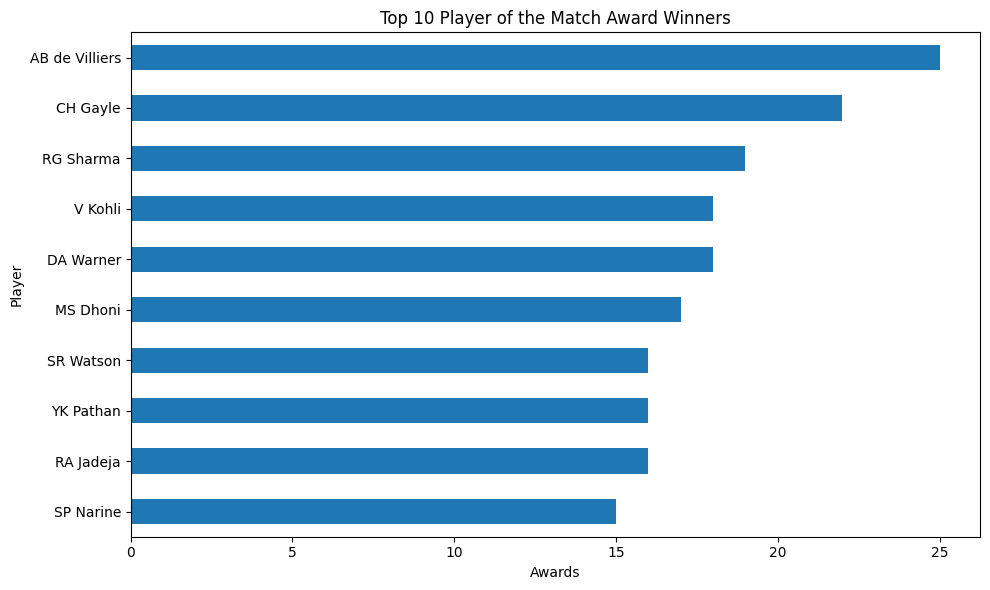

In [48]:
# 5. TOP PLAYER OF THE MATCH AWARDS
plt.figure(figsize=(10,6))
player_of_match.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Player of the Match Award Winners")
plt.xlabel("Awards")
plt.ylabel("Player")
plt.tight_layout()
plt.show()


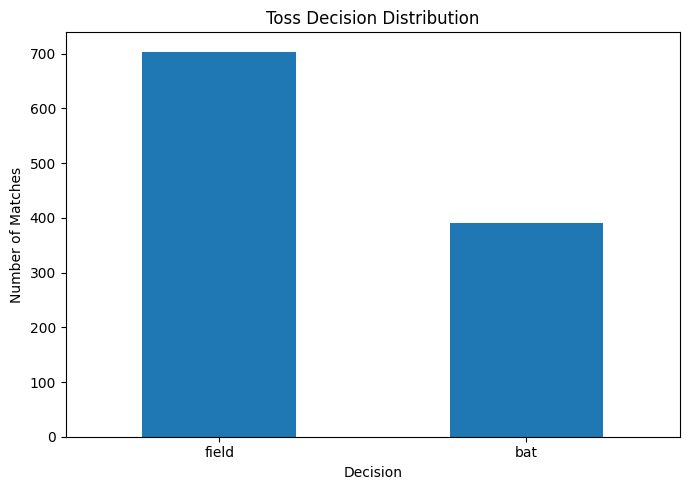

In [49]:
# 6. TOSS DECISION
plt.figure(figsize=(7,5))
toss_decision.plot(kind="bar")
plt.title("Toss Decision Distribution")
plt.xlabel("Decision")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


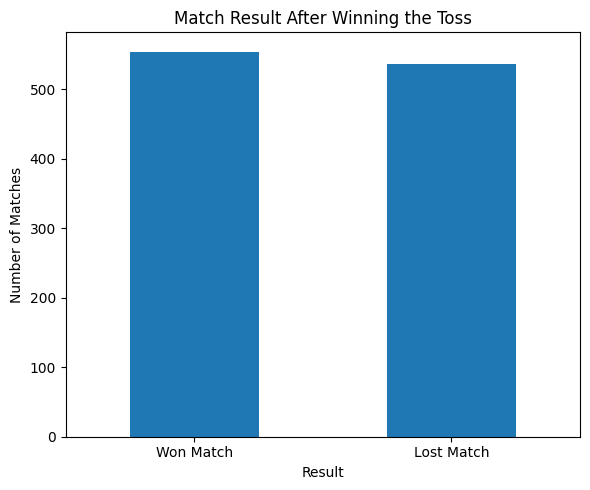

In [50]:
# 7. MATCHES WON AFTER WINNING TOSS
plt.figure(figsize=(6,5))
toss_win_count.rename({True:"Won Match", False:"Lost Match"}).plot(kind="bar")
plt.title("Match Result After Winning the Toss")
plt.xlabel("Result")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


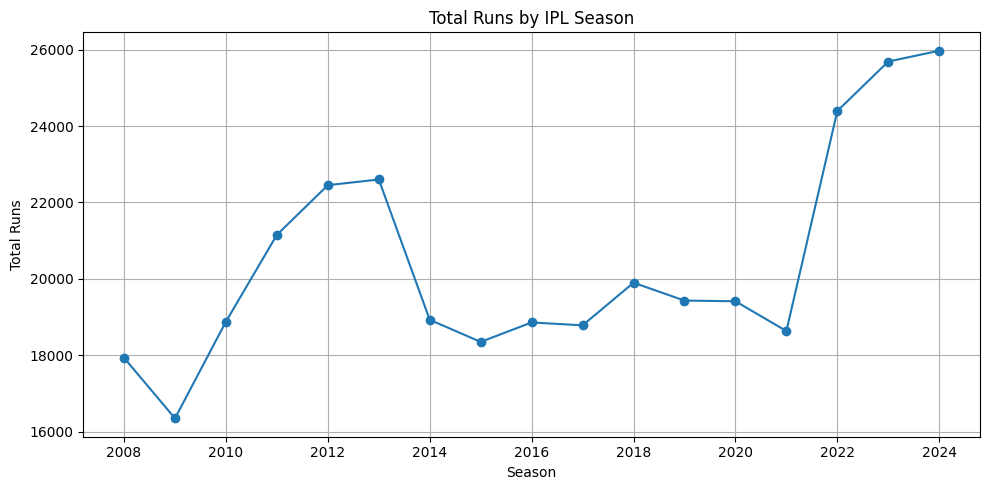

In [52]:
# 8. TOTAL RUNS BY SEASON
plt.figure(figsize=(10,5))
season_runs.plot(kind="line", marker="o")
plt.title("Total Runs by IPL Season")
plt.xlabel("Season")
plt.ylabel("Total Runs")
plt.grid(True)
plt.tight_layout()
plt.show()


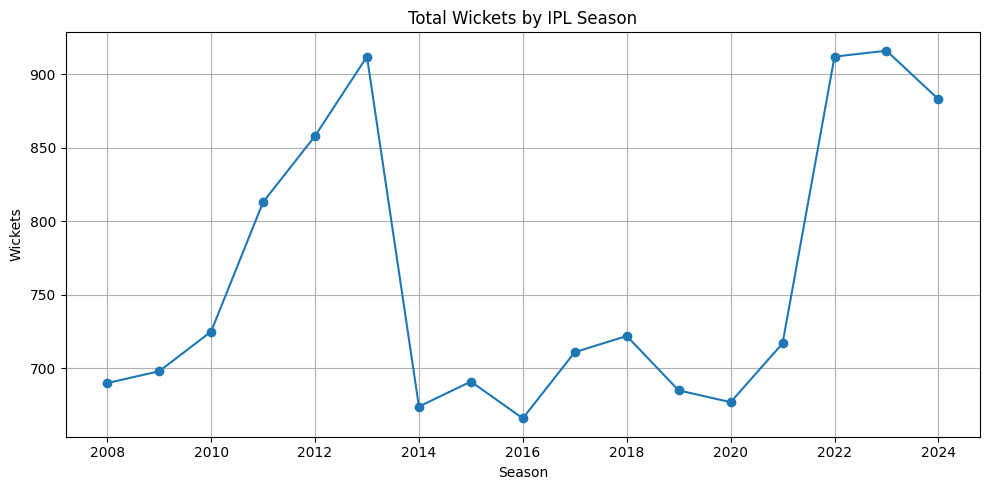

In [51]:
# 9. TOTAL WICKETS BY SEASON
plt.figure(figsize=(10,5))
season_wickets.plot(kind="line", marker="o")
plt.title("Total Wickets by IPL Season")
plt.xlabel("Season")
plt.ylabel("Wickets")
plt.grid(True)
plt.tight_layout()
plt.show()


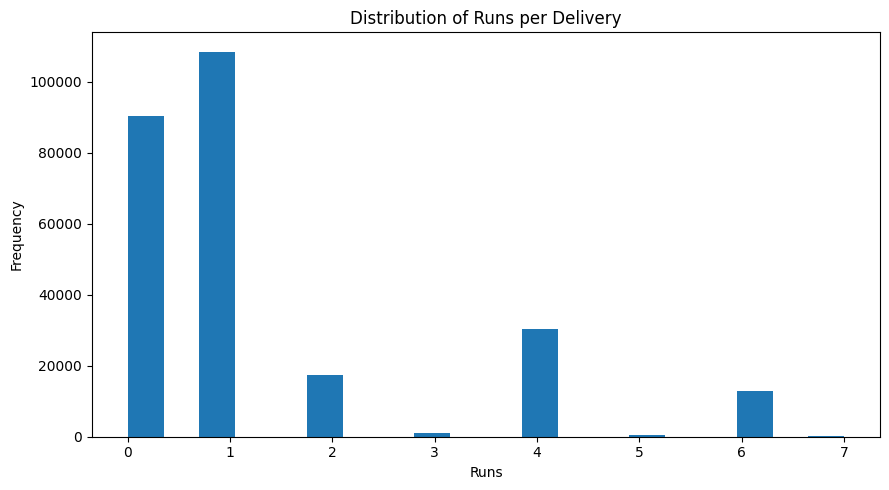

In [54]:
# RUNS HISTOGRAM

plt.figure(figsize=(9, 5))

plt.hist(merged["total_runs"], bins=20)

plt.title("Distribution of Runs per Delivery")
plt.xlabel("Runs")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


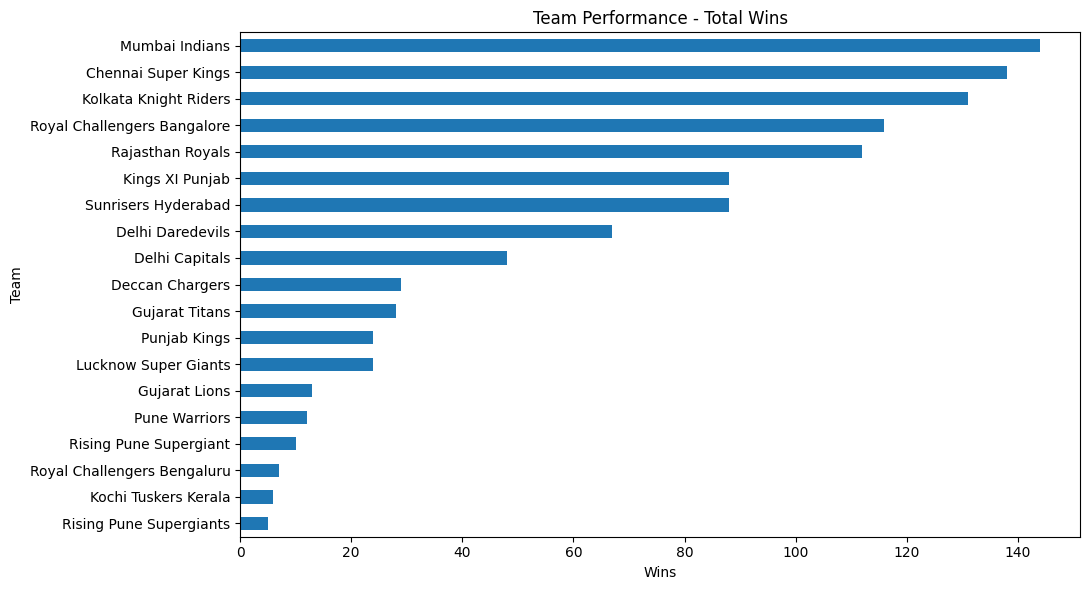

In [55]:
# 11. TEAM PERFORMANCE
plt.figure(figsize=(11,6))
team_performance["Wins"].sort_values().plot(kind="barh")
plt.title("Team Performance - Total Wins")
plt.xlabel("Wins")
plt.ylabel("Team")
plt.tight_layout()
plt.show()


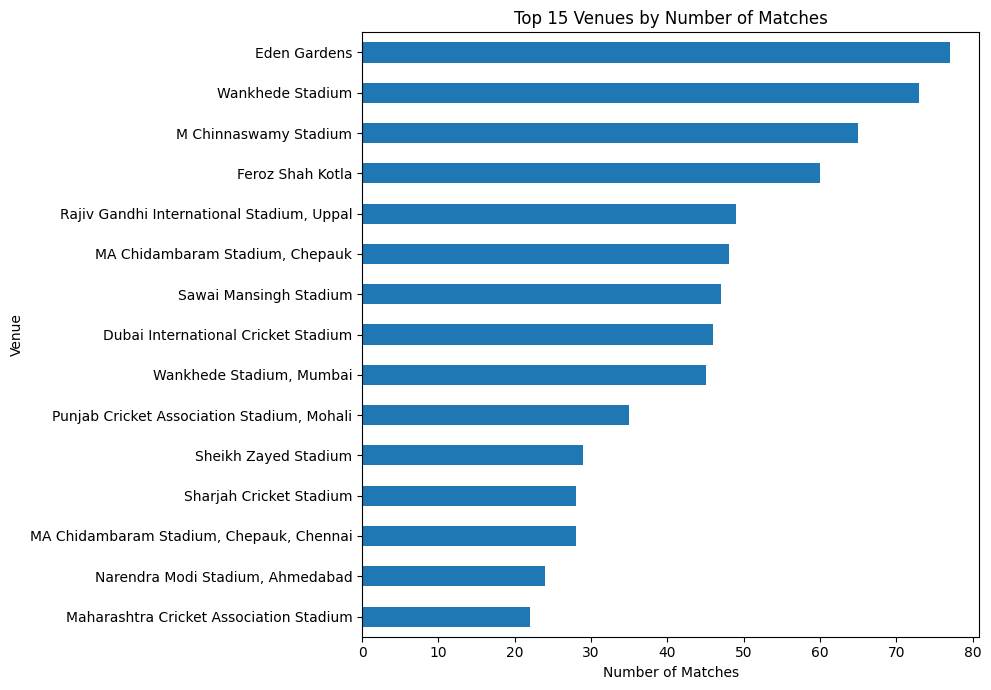

In [56]:
# 12. MATCHES BY VENUE
plt.figure(figsize=(10,7))
venue_count.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Venues by Number of Matches")
plt.xlabel("Number of Matches")
plt.ylabel("Venue")
plt.tight_layout()
plt.show()


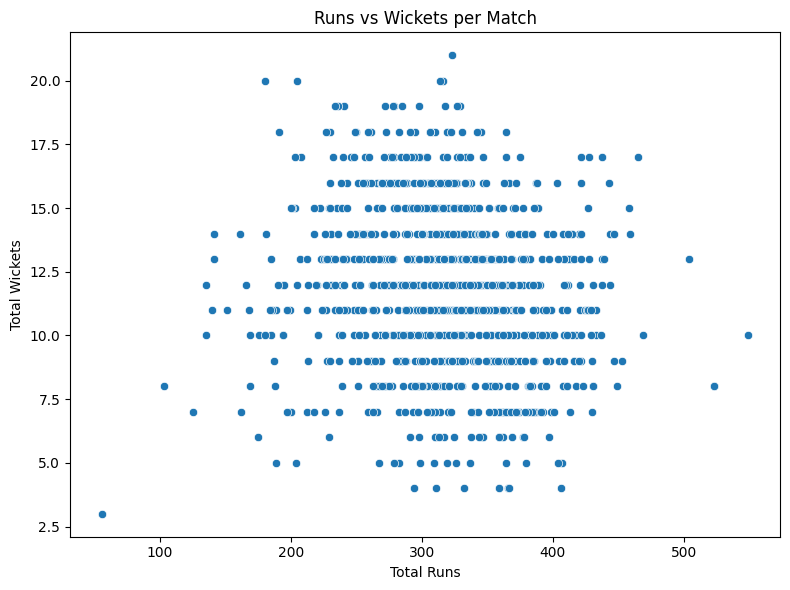

In [59]:
# 13. RUNS VS WICKETS

match_summary = merged.groupby("ID").agg(
    Total_Runs=("total_runs", "sum"),
    Total_Wickets=("is_wicket", "sum")
).reset_index()

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=match_summary,
    x="Total_Runs",
    y="Total_Wickets"
)

plt.title("Runs vs Wickets per Match")
plt.xlabel("Total Runs")
plt.ylabel("Total Wickets")

plt.tight_layout()
plt.show()


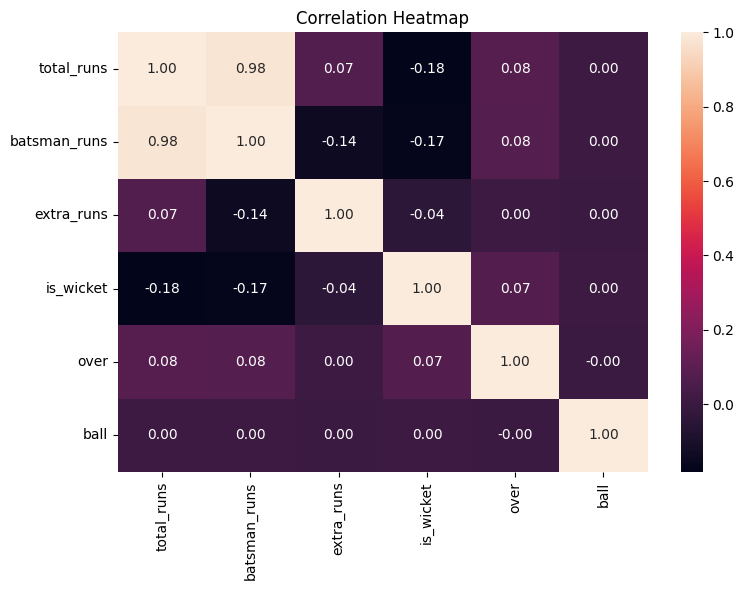

In [60]:
# 14. CORRELATION HEATMAP

numeric_cols = [
    "total_runs",
    "batsman_runs",
    "extra_runs",
    "is_wicket",
    "over",
    "ball"
]

corr_data = merged[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_data,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## 7. ADDITIONAL ANALYSIS


In [32]:
# VENUE PERFORMANCE
venue_performance = matches.groupby("venue").agg(
    Matches=("id","nunique"),
    Wins=("winner","count")
).sort_values("Matches", ascending=False)

display(venue_performance.head(15))


,Matches,Wins
venue,,
Eden Gardens,77,77
Wankhede Stadium,73,73
M Chinnaswamy Stadium,65,63
Feroz Shah Kotla,60,59
"Rajiv Gandhi International Stadium, Uppal",49,49
"MA Chidambaram Stadium, Chepauk",48,48
Sawai Mansingh Stadium,47,47
Dubai International Cricket Stadium,46,46
"Wankhede Stadium, Mumbai",45,45


In [34]:
# TEAM-WISE RUNS

team_runs = (
    merged.groupby("batting_team")["total_runs"]
    .sum()
    .sort_values(ascending=False)
)

display(team_runs)

,total_runs
batting_team,
Mumbai Indians,42176
Kolkata Knight Riders,39331
Chennai Super Kings,38629
Royal Challengers Bangalore,37692
Rajasthan Royals,34747
Kings XI Punjab,30064
Sunrisers Hyderabad,29071
Delhi Daredevils,24296
Delhi Capitals,14900


In [36]:
# TEAM-WISE WICKETS TAKEN

team_wickets = (
    bowling_dismissals.groupby("bowling_team")["is_wicket"]
    .sum()
    .sort_values(ascending=False)
)

display(team_wickets)


,is_wicket
bowling_team,
Mumbai Indians,1591
Chennai Super Kings,1481
Kolkata Knight Riders,1464
Royal Challengers Bangalore,1406
Rajasthan Royals,1277
Kings XI Punjab,1076
Sunrisers Hyderabad,1074
Delhi Daredevils,912
Delhi Capitals,586


In [38]:
# SEASON AVERAGE RUNS PER MATCH

match_runs = (
    merged.groupby("ID")["total_runs"]
    .sum()
)

match_seasons = (
    merged.groupby("ID")["season"]
    .first()
)

season_average_runs = (
    match_runs.groupby(match_seasons)
    .mean()
)

display(season_average_runs)

,total_runs
season,
2008,309.258621
2009,286.894737
2010,314.716667
2011,289.780822
2012,303.418919
2013,297.394737
2014,315.516667
2015,311.067797
2016,314.366667


## 8. KEY INSIGHTS

The following code automatically creates factual insights from the calculated results. This avoids manually typing values and reduces errors.


In [39]:
# AUTOMATIC KEY INSIGHTS
highest_win_team = team_wins.idxmax()
highest_win_count = int(team_wins.max())

top_batter = top_run_scorers.index[0]
top_batter_runs = int(top_run_scorers.iloc[0])

top_bowler = top_wicket_takers.index[0]
top_bowler_wickets = int(top_wicket_takers.iloc[0])

top_pom_player = player_of_match.index[0]
top_pom_count = int(player_of_match.iloc[0])

most_used_venue = venue_count.index[0]
most_used_venue_count = int(venue_count.iloc[0])

highest_run_season = int(season_runs.idxmax())
highest_run_season_total = int(season_runs.max())

print("KEY INSIGHTS")
print(f"1. {highest_win_team} has the highest number of recorded wins: {highest_win_count}.")
print(f"2. {top_batter} is the highest run scorer in the available ball-by-ball data with {top_batter_runs} runs.")
print(f"3. {top_bowler} has the highest number of recorded bowling dismissals with {top_bowler_wickets} wickets.")
print(f"4. {top_pom_player} has the highest number of Player of the Match awards with {top_pom_count}.")
print(f"5. {most_used_venue} has hosted the highest number of matches in this dataset: {most_used_venue_count}.")
print(f"6. Season {highest_run_season} recorded the highest total runs: {highest_run_season_total}.")
print(f"7. The toss winner also won the match in {toss_win_percentage:.2f}% of matches with both values recorded.")


KEY INSIGHTS
1. Mumbai Indians has the highest number of recorded wins: 144.
2. V Kohli                  is the highest run scorer in the available ball-by-ball data with 8014 runs.
3. YS Chahal                has the highest number of recorded bowling dismissals with 213 wickets.
4. AB de Villiers has the highest number of Player of the Match awards with 25.
5. Eden Gardens has hosted the highest number of matches in this dataset: 77.
6. Season 2024 recorded the highest total runs: 25971.
7. The toss winner also won the match in 50.83% of matches with both values recorded.


## 9. EXPORT CLEANED DATA

The project requires a cleaned CSV. The notebook creates it automatically.


In [40]:
# SAVE CLEANED / MERGED DATA
cleaned_file = "IPL_Cleaned.csv"
merged.to_csv(cleaned_file, index=False)

print(f"Created: {cleaned_file}")


Created: IPL_Cleaned.csv


In [42]:
# SAVE SUMMARY TABLES

matches_per_season.to_csv("Matches_Per_Season.csv")
top_run_scorers.head(10).to_csv("Top_10_Run_Scorers.csv")
top_wicket_takers.head(10).to_csv("Top_10_Wicket_Takers.csv")
season_runs.to_csv("Season_Runs.csv")
season_wickets.to_csv("Season_Wickets.csv")
team_runs.to_csv("Team_Runs.csv")
team_wickets.to_csv("Team_Wickets.csv")

print("Summary CSV files created successfully.")

Summary CSV files created successfully.


## 10. POWER BI

After running the notebook, download `IPL_Cleaned.csv` and import it into Power BI Desktop.

### Suggested DAX measures

```DAX
Total Matches = DISTINCTCOUNT(IPL_Cleaned[ID])

Total Runs = SUM(IPL_Cleaned[TotalRun])

Total Wickets = SUM(IPL_Cleaned[IsWicketDelivery])

Total Teams =
DISTINCTCOUNT(IPL_Cleaned[BattingTeam])

Total Players =
DISTINCTCOUNT(IPL_Cleaned[Batter])

Average Runs =
AVERAGE(IPL_Cleaned[TotalRun])

Average Winning Margin =
AVERAGE(IPL_Cleaned[result_margin])
```

### Dashboard visuals

1. KPI cards: Total Matches, Total Runs, Total Wickets, Total Teams, Total Players
2. Matches by Season
3. Team Wins
4. Top 10 Batsmen
5. Top 10 Bowlers
6. Runs by Season
7. Matches by Venue
8. Toss Decision
9. Player of the Match
10. Team Performance
11. Slicers: Season, Team, Venue

These correspond to the dashboard requirements in the project brief.


## 11. FINAL SUBMISSION FILES

After running the notebook, keep these files:

- `IPL_Data_Analysis.ipynb`
- `IPL_Cleaned.csv`
- Power BI `.pbix`
- Project Report PDF
- `README.md`

**Important:** Run all notebook cells before submission so the analysis tables and charts are visible.
